# Lost in Translation: Mandarin to Serbian that keeps who's talking

**Track:** AI + Languages · Round 1 is judged blind, so no names or school anywhere in this notebook.

**How to run it:** in Google Colab, click **Runtime → Run all**. It needs no sign-in, no keys and no uploads, and it gives the same numbers every time. A GPU (Runtime → Change runtime type → T4 GPU) makes the translating faster but isn't required.

## 0. Intro

> Our project helps **a Mandarin speaker writing to Serbian colleagues at work** by taking **a Mandarin sentence plus who is speaking, who they're talking to and how formal it is** and giving back **Serbian with the right endings, or a warning when it had to guess**.

**The problem.** In Serbian, the words change with the speaker's gender ("I checked it" is *Проверио сам* from a man, *Проверила сам* from a woman) and with politeness (*ти си* to a friend, *Ви сте* to a boss). Mandarin marks politeness (您 is the polite "you", 你 the casual one) but usually not the speaker's gender. Many translation tools go through English on the way, and English has one "you" and no gendered verbs, so both get lost and the Serbian tends to come out masculine.

**What we compare,** on the same test sentences that we wrote ourselves:
1. **Baseline:** Mandarin → English → Serbian (two Helsinki-NLP models).
2. **Direct:** Meta's NLLB model, Mandarin straight to Serbian, its top answer.
3. **Ours:** NLLB's top 32 answers, plus rules about Serbian endings that pick the one matching the speaker, listener and formality, or say "had to guess" when none does.

## 1. Setup

Installs three small extras, loads the libraries, fixes the random seed and picks the fastest hardware available.

- `sentencepiece` and `sacremoses` are what the translation models use to cut text into word pieces. `sacrebleu` gives us **chrF**, the translation score in section 7. Colab already has everything else (pandas, PyTorch, transformers, matplotlib).
- A **seed** makes anything random come out the same on every run, so the judges see exactly the numbers in our write-up. Our translations don't use randomness anyway: the models use *beam search*, which always gives the same output for the same input.

In [1]:
# Install the three extras. "-q" (quiet) keeps the output short. Takes a few seconds.
%pip install -q sentencepiece sacremoses sacrebleu

You should consider upgrading via the '/private/tmp/claude-502/-Users-calebmeyer-Library-Application-Support-Claude-scratch-workspaces-c89e8fa9-d4f2-445d-9de6-08e7bd983212-f8390555-62d9-45f2-874e-57dbfbc13608-scratch-2026-11-13-01c776/feae61c6-1443-4f8d-9574-7f938dcd902a/scratchpad/nbtest/bin/python -m pip install --upgrade pip' command.


Note: you may need to restart the kernel to use updated packages.


### Libraries, seed and hardware

Import the libraries, fix the seed, and check for a GPU. With a GPU (in Colab: Runtime → Change runtime type → T4 GPU) translating is several times faster. Without one it still works, just slower.

In [2]:
import os, io, time, random, urllib.request   # built into Python: files, timing, downloads
import numpy as np                 # fast maths on lists of numbers
import pandas as pd                # tables (like a spreadsheet in Python)
import matplotlib.pyplot as plt    # charts
import torch                       # PyTorch: runs the neural translation models
import transformers                # Hugging Face: downloads and runs pre-trained models
import sacrebleu                   # the chrF translation score
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Fix the random seed so every "Run all" gives the same results.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use the GPU if there is one ("cuda" is NVIDIA's name for it); otherwise the CPU.
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on:", DEVICE, "(GPU)" if DEVICE == "cuda" else "(no GPU: slower, but it works)")

# Show whole sentences in tables instead of cutting them off with "...".
pd.set_option("display.max_colwidth", None)

print("pandas", pd.__version__, "| torch", torch.__version__,
      "| transformers", transformers.__version__, "| sacrebleu", sacrebleu.__version__)

/private/tmp/claude-502/-Users-calebmeyer-Library-Application-Support-Claude-scratch-workspaces-c89e8fa9-d4f2-445d-9de6-08e7bd983212-f8390555-62d9-45f2-874e-57dbfbc13608-scratch-2026-11-13-01c776/feae61c6-1443-4f8d-9574-7f938dcd902a/scratchpad/nbtest/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/private/tmp/claude-502/-Users-calebmeyer-Library-Application-Support-Claude-scratch-workspaces-c89e8fa9-d4f2-445d-9de6-08e7bd983212-f8390555-62d9-45f2-874e-57dbfbc13608-scratch-2026-11-13-01c776/feae61c6-1443-4f8d-9574-7f938dcd902a/scratchpad/nbtest/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Running on: cpu (no GPU: slower, but it works)
pandas 2.3.3 | torch 2.8.0 | transformers 4.57.6 | sacrebleu 2.6.0


### Hugging Face token (optional)

We don't need a token: all three models download with no sign-in, and we don't upload anything. This cell is only here in case we ever upload results to Hugging Face. A token would live in Colab's **Secrets** panel (the key icon on the left) under the name `HF_TOKEN`, never in this notebook. Judges won't have it, so everything below works without it.

In [3]:
HF_TOKEN = None
try:
    from google.colab import userdata   # this only exists inside Colab
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    pass  # not in Colab, or no secret set: that's fine, uploading is just skipped

print("Hugging Face token found." if HF_TOKEN else "No Hugging Face token. That's fine: uploading is skipped.")

No Hugging Face token. That's fine: uploading is skipped.


### How we'll score the three systems

Every system is scored the same way, on the same **test** rows, so the comparison is fair. The scoring code comes in section 7; here is what each number means:

- **chrF:** a standard translation score (from the `sacrebleu` library). It compares our Serbian to the correct Serbian our team wrote, counting matching letter sequences, from 0 (nothing alike) to 100 (identical). It's good at noticing a wrong ending, because an ending is only a letter or two.
- **Gender correct %:** of the sentences where the speaker's (or listener's) gender shows in Serbian, how many came out with the right gender ending (for example -о vs -ла).
- **Formality correct %:** how many used the right "you": formal *Ви / сте* or casual *ти / си*.
- **Right form in the 32 options %:** how often at least one of NLLB's top 32 answers had the right gender and formality. This is the best our picker could possibly do, so it shows whether a miss is the picker's fault or the model's.
- **Flag accuracy:** when our system says "had to guess", was it really unable to find the right form? And when it doesn't warn, was it right?
- **Worst misses:** 3-5 sentences where it went most wrong, shown side by side with the correct Serbian, and why we think it happened.

## 2. Data

Our test set is a small table of everyday workplace sentences that our team wrote and labelled ourselves (how we wrote them is in `data/README.md`). We load it from the repo's public web address, never from a file on someone's laptop, so it works in a fresh Colab:

`https://raw.githubusercontent.com/proelium27/veritas-ai-hackathon/main/data/test_sentences.csv`

| Column | What it holds |
|---|---|
| `id` | a unique number for the row |
| `mandarin` | the sentence in Mandarin (simplified characters) |
| `english_meaning` | what it means, in plain English (written by us, not by a model) |
| `speaker_gender` | who is talking: `man` or `woman` |
| `listener_gender` | who they're talking to: `man`, `woman` or `group` |
| `formal` | `yes` if it uses the polite 您 (to a manager), `no` for the casual 你 |
| `what_it_tests` | which Serbian ending the sentence checks: `speaker_gender`, `listener_gender`, `formality`, or `control` (none of them); several are joined with `+` |
| `correct_serbian` | the correct Serbian in Latin letters with the marks (č, ć, š, ž, đ, dž), written by our Serbian speaker without any translation tool |
| `notes` | anything worth knowing, e.g. other correct answers |
| `split` | `practice` (used to build the picker's rules) or `test` (locked until the rules are final) |

**While the repo is still private** the web address doesn't work yet, because GitHub hides private files. So the cell falls back to a local copy: `data/test_sentences.csv` in the repo, or a `test_sentences.csv` uploaded into Colab (folder icon on the left → Upload). The repo must be public before the final check, so the judges load it from the web address.

Every column is read as text (`dtype=str`), so nothing gets changed: `yes`/`no` stay words, and empty cells become empty text instead of "NaN" (pandas' word for a missing value).

In [4]:
DATA_URL = "https://raw.githubusercontent.com/proelium27/veritas-ai-hackathon/main/data/test_sentences.csv"

# Backup places to look if the web address doesn't work yet (the repo is private until we submit).
LOCAL_COPIES = [
    "data/test_sentences.csv",      # running from the repo's top folder
    "../data/test_sentences.csv",   # running from inside the notebook/ folder
    "test_sentences.csv",           # uploaded into Colab's Files panel
]

EXPECTED_COLUMNS = ["id", "mandarin", "english_meaning", "speaker_gender", "listener_gender",
                    "formal", "what_it_tests", "correct_serbian", "notes", "split"]


def read_table(source):
    """Read the CSV with every column as text, and empty cells as empty text ("")."""
    return pd.read_csv(source, dtype=str, keep_default_na=False)


def load_test_set():
    """Return (table, where it came from). Tries the web address first, then the local copies."""
    # 1) The public web address: this is what the judges will use.
    try:
        with urllib.request.urlopen(DATA_URL, timeout=30) as response:
            text = response.read().decode("utf-8")
        return read_table(io.StringIO(text)), DATA_URL
    except Exception as error:
        print(f"Couldn't download the test set from the web address ({error}).")

    # 2) A local copy, while the repo is still private.
    for path in LOCAL_COPIES:
        if os.path.exists(path):
            print(f"Using the local copy at {path} instead.")
            return read_table(path), path

    # 3) Nothing worked: say what to do in plain English, then stop.
    print("We couldn't find our test sentences. Two ways to fix it:\n"
          "  1. Make the GitHub repo public (the judges need that anyway), then run this cell again.\n"
          "  2. While developing: in Colab, click the folder icon on the left, then Upload,\n"
          "     choose test_sentences.csv from the repo's data folder, and run this cell again.")
    raise FileNotFoundError("No test set found. See the message above.")


df, DATA_SOURCE = load_test_set()

# Check the columns are the ones we expect (a spreadsheet export can rename or drop them).
missing_columns = [c for c in EXPECTED_COLUMNS if c not in df.columns]
if missing_columns:
    raise ValueError(f"The test set is missing these columns: {missing_columns}. Compare it with data/README.md.")

# Remove stray spaces around every cell (spreadsheets sometimes add them).
df = df.apply(lambda column: column.str.strip())

print(f"Loaded {len(df)} sentences from: {DATA_SOURCE}")
if DATA_SOURCE != DATA_URL:
    print("Note: that's a local copy for development. The judges load it from the web address,")
    print("so the repo must be public before the final Run all check.")
df.head()

Couldn't download the test set from the web address (HTTP Error 404: Not Found).
Using the local copy at ../data/test_sentences.csv instead.
Loaded 4 sentences from: ../data/test_sentences.csv
Note: that's a local copy for development. The judges load it from the web address,
so the repo must be public before the final Run all check.


,id,mandarin,english_meaning,speaker_gender,listener_gender,formal,what_it_tests,correct_serbian,notes,split
0,ex1,我检查过了。,I checked it.,woman,man,no,speaker_gender,Proverila sam.,"EXAMPLE - delete before use. Woman speaking to a man coworker, informal. Speaker gender shows in the ending: Proverila (woman) vs Proverio (man).",
1,ex2,您昨天来上班了吗？,Did you come to work yesterday?,man,man,yes,formality,Da li ste juče došli na posao?,"EXAMPLE - delete before use. Man speaking to a manager, formal (您 becomes Vi/ste). With formal Vi the verb takes the plural form došli, so the manager's gender does not show; listener set to man just as an example.",
2,ex3,你昨天来上班了吗？,Did you come to work yesterday?,man,woman,no,listener_gender+formality,Da li si juče došla na posao?,"EXAMPLE - delete before use. Man speaking to a woman coworker, informal (你 becomes ti/si). Listener gender shows: došla (to a woman) vs došao (to a man).",
3,ex4,我已经把机器关了。,I already turned the machine off.,woman,woman,yes,speaker_gender,Već sam isključila mašinu.,"EXAMPLE - delete before use. Woman speaking to a manager, formal. There is no 'you' in the sentence, so only speaker gender shows: isključila (woman) vs isključio (man). Listener set to woman just as an example.",


## 3. Explore

Before translating anything, we count the sentences by each label. This checks the set isn't lopsided: if almost every speaker were a man, a system that always writes the masculine ending would look good without being good. A blank `split` means the row is one of the example rows.

In [5]:
def tests_property(what_it_tests, prop):
    """True if a row's what_it_tests (e.g. "speaker_gender+formality") includes prop."""
    return prop in what_it_tests.split("+")

# One small table per label: how many rows have each value.
for column in ["what_it_tests", "speaker_gender", "listener_gender", "formal", "split"]:
    counts = df[column].replace("", "(blank)").value_counts().rename("rows").to_frame()
    display(counts)

# A row can test more than one thing, so also count rows per property.
print("Rows that test each property (a row can test more than one):")
for prop in ["speaker_gender", "listener_gender", "formality", "control"]:
    n = df["what_it_tests"].apply(tests_property, prop=prop).sum()
    print(f"  {prop:16s} {n}")

# Rows without the correct Serbian can be translated, but not scored.
no_serbian = (df["correct_serbian"] == "").sum()
print(f"\nRows still missing correct_serbian: {no_serbian} of {len(df)}")

,rows
what_it_tests,
speaker_gender,2
formality,1
listener_gender+formality,1


,rows
speaker_gender,
woman,2
man,2


,rows
listener_gender,
man,2
woman,2


,rows
formal,
no,2
yes,2


,rows
split,
(blank),4


Rows that test each property (a row can test more than one):
  speaker_gender   2
  listener_gender  1
  formality        2
  control          0

Rows still missing correct_serbian: 0 of 4


### The same counts as a chart

One bar chart per label, side by side, so a lopsided label stands out at a glance.

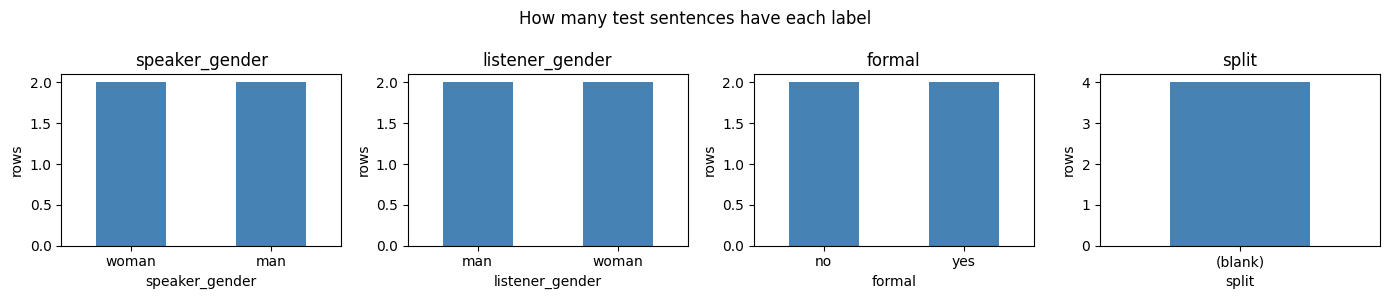

In [6]:
chart_columns = ["speaker_gender", "listener_gender", "formal", "split"]
fig, axes = plt.subplots(1, len(chart_columns), figsize=(14, 3))
for ax, column in zip(axes, chart_columns):
    df[column].replace("", "(blank)").value_counts().plot.bar(ax=ax, color="steelblue")
    ax.set_title(column)
    ax.set_ylabel("rows")
    ax.tick_params(axis="x", rotation=0)
fig.suptitle("How many test sentences have each label")
plt.tight_layout()
plt.show()

## 4. Split: practice rows and test rows

We use the `split` column exactly as our team set it when writing the sentences; we never reshuffle it or move a row after seeing results.

- **practice** (about 20 rows): we look at these freely and use them to write and check the picker's rules about Serbian endings.
- **test** (the rest): locked. **Nobody looks at results on the test rows until the picker's rules are final.** Otherwise we could tweak the rules until they fit the test sentences, and the score would look better than the system really is. So the tables in sections 5-7 hide test rows, and section 7 only scores them when we deliberately switch `SHOW_TEST_RESULTS` on, once.
- **example** (blank `split`): the 4 example rows from `data/README.md`. They are in neither group.

**`USE_EXAMPLES` switch:** until the real sentences arrive, `USE_EXAMPLES = True` runs the whole pipeline on the 4 example rows, just to show it works. Set it to `False` once the real practice and test rows are in the CSV.

In [7]:
USE_EXAMPLES = True   # True: demo on the 4 example rows. Set to False once the real sentences are in.

# Rows with an empty split are the example rows.
df["split"] = df["split"].replace("", "example")

practice = df[df.split == "practice"]
test     = df[df.split == "test"]
examples = df[df.split == "example"]
print(f"practice rows: {len(practice)} | test rows: {len(test)} | example rows: {len(examples)}")

# Anything else in the split column is probably a typo: show it so someone fixes the CSV.
odd = df[~df.split.isin(["practice", "test", "example"])]
if len(odd):
    print("These rows have an unexpected split value and are left out:")
    display(odd[["id", "split"]])

# "work" is the set of rows we translate in sections 5 and 6.
if USE_EXAMPLES:
    work = examples.copy()
    print("USE_EXAMPLES is on: translating only the example rows, as a demo.")
else:
    work = pd.concat([practice, test]).copy()
    print("Translating all practice and test rows. Test results stay hidden until the rules are final.")

if len(work) == 0:
    raise ValueError("No rows to translate. If the example rows were deleted, set USE_EXAMPLES = False.")
work = work.reset_index(drop=True)

# Tables below only show rows that are not locked test rows.
def visible(table):
    return table[table.split != "test"]

practice rows: 0 | test rows: 0 | example rows: 4
USE_EXAMPLES is on: translating only the example rows, as a demo.


## 5. Baseline: through English

Many translation apps go through English. We copy that with two pre-trained models:

1. `Helsinki-NLP/opus-mt-zh-en` translates Mandarin → English.
2. `Helsinki-NLP/opus-mt-tc-base-en-sh` translates English → Serbian. This one model covers Serbian, Croatian and Bosnian, so each input starts with `>>srp_Cyrl<<` to ask for Serbian in Cyrillic letters.

We expect this route to lose the speaker's gender and the formal/casual "you", because English doesn't have them. We keep the English in the middle (`english_model`) so you can see where the information disappears.

First, two helpers we use for every model. `load()` downloads a model and its **tokenizer** (the part that cuts text into the word pieces the model reads). `translate()` runs a model on a list of sentences, a batch at a time, using **beam search**: the model keeps its best few guesses at each step and returns the best ones, most likely first.

In [8]:
def load(name, **tokenizer_options):
    """Download a translation model and its tokenizer (only the first time), and put it on DEVICE."""
    start = time.time()
    tokenizer = AutoTokenizer.from_pretrained(name, **tokenizer_options)
    model = AutoModelForSeq2SeqLM.from_pretrained(name).to(DEVICE).eval()   # eval() = use it, not train it
    print(f"Loaded {name} in {time.time() - start:.0f} s")
    return tokenizer, model


def translate(tokenizer, model, texts, n_options=1, batch_size=16, **generate_options):
    """Translate a list of sentences.
    Returns one list per sentence holding its n_options best translations, best first."""
    results = []
    for start in range(0, len(texts), batch_size):              # a batch of sentences at a time
        chunk = texts[start:start + batch_size]
        batch = tokenizer(chunk, return_tensors="pt", padding=True).to(DEVICE)
        with torch.no_grad():                                      # no training, so skip the extra maths
            output = model.generate(**batch,
                                    num_beams=max(4, n_options),   # how many guesses beam search keeps
                                    num_return_sequences=n_options,
                                    max_new_tokens=128,            # plenty for one short sentence
                                    **generate_options)
        decoded = tokenizer.batch_decode(output, skip_special_tokens=True)
        # The model returns one flat list; regroup it into n_options per sentence.
        for i in range(len(chunk)):
            results.append(decoded[i * n_options:(i + 1) * n_options])
    return results

### Serbian in Latin letters: `to_latin()`

Serbian is written in two alphabets, Cyrillic and Latin, and our correct answers are in **Latin** (with the marks č, ć, š, ž, đ, dž). But the models can only write Serbian in **Cyrillic**: NLLB has a "Serbian, Cyrillic" setting (`srp_Cyrl`) and no "Serbian, Latin" one (its Latin options are Croatian and Bosnian, which are different languages with different words), and we ask the English → Serbian model for Cyrillic too.

That's not a problem, because the two Serbian alphabets match **letter for letter**: ш is always š, ч is always č, and three Cyrillic letters become two Latin ones (љ → lj, њ → nj, џ → dž). So converting is exact, with no guessing and nothing lost. Every model answer is converted to Latin as soon as it's produced, and the Cyrillic original is kept in an extra column ending in `_cyrillic`. The cell also tests the conversion on a few words.

In [9]:
# Serbian Cyrillic -> Latin, one letter at a time (small letters first).
CYRILLIC_TO_LATIN = {
    "а": "a", "б": "b", "в": "v", "г": "g", "д": "d", "ђ": "đ", "е": "e", "ж": "ž", "з": "z", "и": "i",
    "ј": "j", "к": "k", "л": "l", "љ": "lj", "м": "m", "н": "n", "њ": "nj", "о": "o", "п": "p", "р": "r",
    "с": "s", "т": "t", "ћ": "ć", "у": "u", "ф": "f", "х": "h", "ц": "c", "ч": "č", "џ": "dž", "ш": "š",
}
# Capital letters: Ш -> Š, and Љ -> "Lj" (not "LJ"), because a capital usually just starts a word.
CYRILLIC_TO_LATIN.update({cyr.upper(): lat.capitalize() for cyr, lat in list(CYRILLIC_TO_LATIN.items())})


def to_latin(text):
    """Write Serbian Cyrillic in Latin letters. Anything else (Latin, punctuation, spaces) stays as it is."""
    return "".join(CYRILLIC_TO_LATIN.get(letter, letter) for letter in text)


# Test it on a few words where we know the right answer.
checks = {"Проверила сам": "Proverila sam", "Љубав": "Ljubav", "Џеп": "Džep", "Ђак": "Đak",
          "Ћерка": "Ćerka", "Чаша, шешир, жут, цвет, јуче": "Čaša, šešir, žut, cvet, juče",
          "Њива": "Njiva", "Already Latin: šta": "Already Latin: šta"}
for cyrillic, expected in checks.items():
    result = to_latin(cyrillic)
    print("ok " if result == expected else "WRONG", f"{cyrillic} -> {result}")
    assert result == expected, f"to_latin({cyrillic!r}) gave {result!r}, expected {expected!r}"

ok  Проверила сам -> Proverila sam
ok  Љубав -> Ljubav
ok  Џеп -> Džep
ok  Ђак -> Đak
ok  Ћерка -> Ćerka
ok  Чаша, шешир, жут, цвет, јуче -> Čaša, šešir, žut, cvet, juče
ok  Њива -> Njiva
ok  Already Latin: šta -> Already Latin: šta


### Load the two baseline models

Each is loaded once and reused for every sentence. The first run downloads them (about 300 MB each), which takes a minute or two.

In [10]:
zh_en_tok, zh_en = load("Helsinki-NLP/opus-mt-zh-en")           # Mandarin -> English
en_sr_tok, en_sr = load("Helsinki-NLP/opus-mt-tc-base-en-sh")   # English -> Serbian/Croatian/Bosnian

Loaded Helsinki-NLP/opus-mt-zh-en in 1 s


Loaded Helsinki-NLP/opus-mt-tc-base-en-sh in 1 s


### Translate every row through English

Step 1 gives `english_model`, step 2 gives the Serbian: `baseline` in Latin letters (what we score) and `baseline_cyrillic` (what the model wrote). The table shows them next to our correct Serbian. Test rows are translated too, but hidden.

In [11]:
start = time.time()
mandarin = work["mandarin"].tolist()

# Step 1: Mandarin -> English (take the top answer for each sentence).
work["english_model"] = [options[0] for options in translate(zh_en_tok, zh_en, mandarin)]

# Step 2: English -> Serbian. ">>srp_Cyrl<<" asks for Serbian in Cyrillic.
english_inputs = [">>srp_Cyrl<< " + english for english in work["english_model"]]
work["baseline_cyrillic"] = [options[0] for options in translate(en_sr_tok, en_sr, english_inputs)]
work["baseline"] = work["baseline_cyrillic"].apply(to_latin)   # Latin, like our correct answers

print(f"Baseline: translated {len(work)} sentences in {time.time() - start:.1f} s")
visible(work)[["id", "mandarin", "english_meaning", "english_model", "baseline", "correct_serbian"]]

Baseline: translated 4 sentences in 0.2 s


,id,mandarin,english_meaning,english_model,baseline,correct_serbian
0,ex1,我检查过了。,I checked it.,I checked.,Proverio sam.,Proverila sam.
1,ex2,您昨天来上班了吗？,Did you come to work yesterday?,Did you come to work yesterday?,Da li ste došli na posao juče?,Da li ste juče došli na posao?
2,ex3,你昨天来上班了吗？,Did you come to work yesterday?,Did you come to work yesterday?,Da li ste došli na posao juče?,Da li si juče došla na posao?
3,ex4,我已经把机器关了。,I already turned the machine off.,I've turned the machine off.,Isključio sam mašinu.,Već sam isključila mašinu.


## 6. Main model: NLLB direct, then NLLB + our picker

`facebook/nllb-200-distilled-600M` (NLLB, "No Language Left Behind", by Meta) translates directly between 200 languages, so Mandarin (`zho_Hans`) goes straight to Serbian in Cyrillic (`srp_Cyrl`) with no English in the middle.

We ask NLLB for its **top 32** answers per sentence (`options`), using beam search with 32 guesses. We tested 8, 16 and 32 in `more_options.ipynb`: with 32, a version with the right ending was there for 91% of sentences, against 80% with 8, and it is still fast. Its first answer is the **direct** system. As with the baseline, every answer is converted to Latin letters with `to_latin()`; the Cyrillic originals are kept in `options_cyrillic` and `direct_cyrillic`. The 32 options are what our picker chooses from, so we also save them to a CSV file that teammates can open and reuse without running the model again.

In [12]:
# src_lang tells the tokenizer the input is Mandarin in simplified characters.
nllb_tok, nllb = load("facebook/nllb-200-distilled-600M", src_lang="zho_Hans")

# NLLB must be told the output language: we force the first word to be the "Serbian, Cyrillic" tag.
SERBIAN = nllb_tok.convert_tokens_to_ids("srp_Cyrl")

Loaded facebook/nllb-200-distilled-600M in 2 s


### Translate every row directly: top 32 options, and the top answer as "direct"

In [13]:
N_OPTIONS = 32

start = time.time()
work["options_cyrillic"] = translate(nllb_tok, nllb, work["mandarin"].tolist(),
                                     n_options=N_OPTIONS, forced_bos_token_id=SERBIAN)
# Convert every option to Latin letters (see to_latin in section 5).
work["options"] = [[to_latin(option) for option in options] for options in work["options_cyrillic"]]
work["direct_cyrillic"] = [options[0] for options in work["options_cyrillic"]]
work["direct"] = [options[0] for options in work["options"]]   # NLLB's single best answer, in Latin
print(f"NLLB: {N_OPTIONS} options for each of {len(work)} sentences in {time.time() - start:.1f} s")

visible(work)[["id", "mandarin", "direct", "correct_serbian"]]

NLLB: 32 options for each of 4 sentences in 2.3 s


,id,mandarin,direct,correct_serbian
0,ex1,我检查过了。,Proverio sam.,Proverila sam.
1,ex2,您昨天来上班了吗？,Da li ste došli na posao juče?,Da li ste juče došli na posao?
2,ex3,你昨天来上班了吗？,Da li si juče došao na posao?,Da li si juče došla na posao?
3,ex4,我已经把机器关了。,Ja sam ga isključio.,Već sam isključila mašinu.


### Save the 32 options to CSV files

One row per sentence, with columns `option_1` to `option_8` (in Latin letters, like our correct answers). Practice and example rows go in one file, which our Serbian speaker can read while writing the picker's rules. Test rows go in a separate file marked LOCKED, which nobody opens until the rules are final. In Colab, the files appear in the `outputs` folder of the Files panel (folder icon on the left), where you can download them.

In [14]:
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Spread the list of options into one column per option.
options_table = work[["id", "split", "mandarin", "speaker_gender", "listener_gender", "formal"]].copy()
for k in range(N_OPTIONS):
    options_table[f"option_{k + 1}"] = [options[k] for options in work["options"]]

files = {
    "nllb_options.csv": options_table[options_table.split != "test"],
    "nllb_options_TEST_LOCKED.csv": options_table[options_table.split == "test"],
}
for filename, table in files.items():
    if len(table):
        path = os.path.join(OUTPUT_DIR, filename)
        table.to_csv(path, index=False, encoding="utf-8")
        print(f"Saved {len(table)} rows to {path}")

Saved 4 rows to outputs/nllb_options.csv


### To do: picker (Phase 4)

**Not built yet.** Our Serbian speaker is writing the picker's rules using only the practice rows. The finished `pick()` will read the Serbian endings of each of the 32 options, in Latin letters (for example -o vs -la after sam for "I did", Vi/ste vs ti/si for "you") and return the first option that matches the row's speaker gender, listener gender and formality, with the note "matched". If none matches, it returns NLLB's top answer with the note **"had to guess"**.

For now, `pick()` below is a **placeholder** that always returns the top answer and "had to guess", so the notebook runs from top to bottom. Until it's replaced, "NLLB + picker" gives exactly the same answers as "NLLB direct".

In [15]:
def pick(options, row):
    """PLACEHOLDER until Phase 4: always the top option, flagged "had to guess".
    options: NLLB's 8 Serbian translations in Latin letters, best first.
    row: that sentence's row, with speaker_gender, listener_gender, formal and what_it_tests.
    Returns (the chosen Serbian, a note)."""
    return options[0], "had to guess"


chosen, notes = [], []
for _, row in work.iterrows():
    choice, note = pick(row["options"], row)
    chosen.append(choice)
    notes.append(note)
work["picked"] = chosen
work["pick_note"] = notes

visible(work)[["id", "mandarin", "picked", "pick_note", "correct_serbian"]]

,id,mandarin,picked,pick_note,correct_serbian
0,ex1,我检查过了。,Proverio sam.,had to guess,Proverila sam.
1,ex2,您昨天来上班了吗？,Da li ste došli na posao juče?,had to guess,Da li ste juče došli na posao?
2,ex3,你昨天来上班了吗？,Da li si juče došao na posao?,had to guess,Da li si juče došla na posao?
3,ex4,我已经把机器关了。,Ja sam ga isključio.,had to guess,Već sam isključila mašinu.


## 7. Evaluate

The scoring helpers, then one results table comparing the three systems on the same rows.

All three systems' answers are already in Latin letters (section 5). The helpers also run `to_latin()` on our correct Serbian, so a cell typed in Cyrillic by mistake still compares Latin to Latin (Latin text passes through unchanged).

- **`chrf(hyps, refs)`** uses `sacrebleu` to compare each translation (a *hypothesis*) with our correct Serbian (the *reference*), 0 to 100. It gives one score for the whole set (corpus chrF, the standard way to report it) and one score per sentence (handy for finding the worst misses).
- **`exact_match(hyps, refs)`**: % of translations identical to our correct Serbian, ignoring extra spaces. Strict, because a sentence can be right in a different word order, but easy to understand.
- **`detect(serbian)`** reads a Serbian sentence and says which speaker gender, listener gender and formality it shows, or `None` when it can't tell.
- **Gender correct %** and **formality correct %** compare `detect()` with our labels, only on rows whose `what_it_tests` includes that property (control rows don't count). Rows where `detect()` returns `None` are skipped, and the table says how many.

Only rows that have a correct Serbian are scored.

In [16]:
def chrf(hyps, refs):
    """chrF from sacrebleu, with both sides in Latin letters (to_latin is from section 5).
    Returns (one score for the whole set, a list with one score per sentence)."""
    hyps = [to_latin(h) for h in hyps]
    refs = [to_latin(r) for r in refs]
    corpus = sacrebleu.corpus_chrf(hyps, [refs]).score
    per_sentence = [sacrebleu.sentence_chrf(h, [r]).score for h, r in zip(hyps, refs)]
    return corpus, per_sentence


def exact_match(hyps, refs):
    """% of translations identical to the reference, in Latin letters and ignoring extra spaces."""
    def tidy(text):
        return " ".join(to_latin(text).split())
    matches = [tidy(h) == tidy(r) for h, r in zip(hyps, refs)]
    return 100 * sum(matches) / len(matches)

### Reading the endings: `detect()` (placeholder)

**This `detect()` is a placeholder. It will be replaced by Adam's rules (see `more_options.ipynb`).** For now it always says "can't tell" (`None`), so every gender and formality check below is skipped and those columns show "n/a".

It reads Serbian in **Latin letters** (the same as every system's answer and our correct Serbian). The real one must return the same kind of answer as our labels: `speaker` is `"man"` or `"woman"`, `listener` is `"man"`, `"woman"` or `"group"`, `formal` is `"yes"` or `"no"`, and any of them can be `None` when the sentence doesn't show it.

In [17]:
def detect(serbian):
    """PLACEHOLDER: will be replaced by Adam's rules (see more_options.ipynb).
    serbian: one sentence in Latin letters, e.g. "Proverila sam."
    Returns which speaker gender, listener gender and formality it shows (None = can't tell)."""
    return dict(speaker=None, listener=None, formal=None)


# Which detect() answer goes with which label column, for each property in what_it_tests.
PROPERTY_CHECKS = {
    "speaker_gender":  ("speaker",  "speaker_gender"),
    "listener_gender": ("listener", "listener_gender"),
    "formality":       ("formal",   "formal"),
}


def property_correct(hyps, rows, properties):
    """Of the rows that test any of `properties`, the % where detect() agrees with all their labels.
    Rows where detect() can't tell (None) are skipped. Returns (% correct, rows checked, rows skipped)."""
    correct = checked = skipped = 0
    for serbian, (_, row) in zip(hyps, rows.iterrows()):
        applies = [p for p in properties if tests_property(row["what_it_tests"], p)]
        if not applies:
            continue                       # this row doesn't test the property, e.g. a control row
        found = detect(serbian)
        pairs = [(found[PROPERTY_CHECKS[p][0]], row[PROPERTY_CHECKS[p][1]]) for p in applies]
        if any(guess is None for guess, label in pairs):
            skipped += 1                   # detect() couldn't tell, so we can't score this row
            continue
        checked += 1
        if all(guess == label for guess, label in pairs):
            correct += 1
    percent = 100 * correct / checked if checked else float("nan")   # nan = nothing to score
    return percent, checked, skipped

### Which rows we score

- With `USE_EXAMPLES = True`: the example rows.
- Otherwise: the **practice** rows only, while the picker is still being written.
- `SHOW_TEST_RESULTS = True` scores the **test** rows instead. Switch it on **once**, after the picker's rules are final, and report those numbers whatever they are. If we change the rules after seeing them, we say so in our log and write-up.

In [18]:
SHOW_TEST_RESULTS = False   # leave False until the picker's rules are final

if USE_EXAMPLES:
    score_split = "example"
elif SHOW_TEST_RESULTS:
    score_split = "test"
else:
    score_split = "practice"

in_split = work[work.split == score_split]
scored = in_split[in_split["correct_serbian"] != ""].copy()
print(f"Scoring the {score_split} rows: {len(scored)} have a correct Serbian "
      f"({len(in_split) - len(scored)} without one are left out).")

Scoring the example rows: 4 have a correct Serbian (0 without one are left out).


### Results table

One row per system, all scored on the same rows. In the gender and formality columns, "checked" is how many rows `detect()` could read and "skipped" how many it couldn't.

In [19]:
SYSTEMS = {
    "Through English (baseline)": "baseline",
    "NLLB direct": "direct",
    "NLLB + picker (ours)": "picked",
}
GENDER = ["speaker_gender", "listener_gender"]
FORMALITY = ["formality"]

if len(scored) == 0:
    print("No rows to score yet: the correct Serbian hasn't been filled in for these rows.")
else:
    refs = scored["correct_serbian"].tolist()
    table_rows = []
    for name, column in SYSTEMS.items():
        hyps = scored[column].tolist()
        corpus_chrf, per_sentence = chrf(hyps, refs)
        scored[f"chrF {column}"] = per_sentence          # keep per-sentence scores for the worst misses
        gender_pct, gender_checked, gender_skipped = property_correct(hyps, scored, GENDER)
        formal_pct, formal_checked, formal_skipped = property_correct(hyps, scored, FORMALITY)
        table_rows.append({
            "system": name,
            "rows scored": len(scored),
            "chrF": corpus_chrf,
            "exact match %": exact_match(hyps, refs),
            "gender correct %": gender_pct,
            "gender checked": gender_checked,
            "gender skipped": gender_skipped,
            "formality correct %": formal_pct,
            "formality checked": formal_checked,
            "formality skipped": formal_skipped,
        })
    results = pd.DataFrame(table_rows).set_index("system").round(1)
    display(results.astype(object).fillna("n/a"))       # "n/a" where there was nothing to check

    if USE_EXAMPLES:
        print("Note: these numbers come from the 4 example rows only. They are a demo that the pipeline "
              "runs from start to finish,\nnot a result: 4 sentences are far too few to compare systems.")
    print("Gender and formality show n/a while detect() is still the placeholder.")

/var/folders/gx/stqy3wqx5s1b_f8z2lxvyzdc0000gp/T/ipykernel_3579/376656785.py:33: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  display(results.astype(object).fillna("n/a"))       # "n/a" where there was nothing to check


,rows scored,chrF,exact match %,gender correct %,gender checked,gender skipped,formality correct %,formality checked,formality skipped
system,,,,,,,,,
Through English (baseline),4,59.2,0.0,n/a,0,3,n/a,0,2
NLLB direct,4,62.8,0.0,n/a,0,3,n/a,0,2
NLLB + picker (ours),4,62.8,0.0,n/a,0,3,n/a,0,2


Note: these numbers come from the 4 example rows only. They are a demo that the pipeline runs from start to finish,
not a result: 4 sentences are far too few to compare systems.
Gender and formality show n/a while detect() is still the placeholder.


### Sentence by sentence

Each system's Serbian next to the correct one, with its chrF for that sentence. Low scores are where to look for the worst misses.

In [20]:
if len(scored):
    columns = ["id", "correct_serbian"]
    for column in SYSTEMS.values():
        columns += [column, f"chrF {column}"]
    display(scored[columns].round(1))

,id,correct_serbian,baseline,chrF baseline,direct,chrF direct,picked,chrF picked
0,ex1,Proverila sam.,Proverio sam.,56.3,Proverio sam.,56.3,Proverio sam.,56.3
1,ex2,Da li ste juče došli na posao?,Da li ste došli na posao juče?,76.2,Da li ste došli na posao juče?,76.2,Da li ste došli na posao juče?,76.2
2,ex3,Da li si juče došla na posao?,Da li ste došli na posao juče?,52.4,Da li si juče došao na posao?,77.9,Da li si juče došao na posao?,77.9
3,ex4,Već sam isključila mašinu.,Isključio sam mašinu.,49.2,Ja sam ga isključio.,35.0,Ja sam ga isključio.,35.0


## 8. Demo

*To do:* One cell where you type a Mandarin sentence and choose who is speaking (man/woman), who you're talking to (man/woman) and formal or casual. It shows the Serbian from our system, plus a warning when it had to guess. Showing the baseline's answer next to it makes the difference easy to see. This is what we film for the video.

## 9. Limits and credits

**What it can't do:** *to do, from our real results.* Things we already expect: the test set is small (60-80 sentences) and only covers workplace messages; the picker only checks endings it has rules for, so it can miss gender shown in other words; it can only pick from NLLB's 32 options, so if none is right it can't fix the sentence; and the user has to tell it the speaker's and listener's gender, because Mandarin usually doesn't say.

**Credits**
- Data: our own test sentences, written and labelled by our team (`data/test_sentences.csv` in this repo).
- Pre-trained models (from Hugging Face, used as they are):
  - [Helsinki-NLP/opus-mt-zh-en](https://huggingface.co/Helsinki-NLP/opus-mt-zh-en), CC BY 4.0
  - [Helsinki-NLP/opus-mt-tc-base-en-sh](https://huggingface.co/Helsinki-NLP/opus-mt-tc-base-en-sh), CC BY 4.0
  - [facebook/nllb-200-distilled-600M](https://huggingface.co/facebook/nllb-200-distilled-600M), CC BY-NC 4.0 (non-commercial use)
- Libraries: [numpy](https://numpy.org/), [pandas](https://pandas.pydata.org/), [scikit-learn](https://scikit-learn.org/), [matplotlib](https://matplotlib.org/), [transformers](https://github.com/huggingface/transformers), [PyTorch](https://pytorch.org/), [sacrebleu](https://github.com/mjpost/sacrebleu), [sentencepiece](https://github.com/google/sentencepiece), [sacremoses](https://github.com/hplt-project/sacremoses)
- AI tools: *to do (name each tool and what we used it for)*